In [20]:
import torch
import os
import matplotlib.pyplot as plt
import numpy as np
import torchvision

In [ ]:
path = "/home/bergmann/Gluon1/Experiments-estimating-smoothness-for-NanoGPT-and-CNN/"
cifar_base_path = os.path.join(path, "cifar10")
cifar_path = os.path.join(cifar_base_path, "train.pt")
data_cifar = torch.load(cifar_path, map_location=torch.device("cuda"))

images_cif, labels_cif, classes_cif = data_cifar["images"], data_cifar["labels"], data_cifar["classes"]
images_cif = (images_cif.float() / 255).permute(0, 3, 1, 2).to(memory_format=torch.channels_last)

In [36]:
images_cif.shape

torch.Size([50000, 3, 32, 32])

/tmp/ipykernel_2773175/3970613016.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image_0 = np.array(image_0)


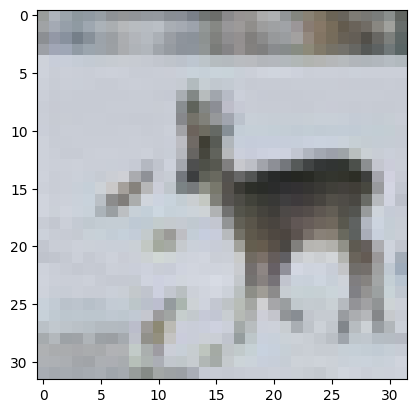

In [37]:
image_0 = images_cif[20].permute(1, 2, 0).cpu()
image_0 = np.array(image_0)
plt.imshow(image_0)

In [38]:
mnist_base_path = os.path.join(path, "mnist")
mnist_train_path = os.path.join(mnist_base_path, "train.pt")
dset = torchvision.datasets.MNIST(mnist_base_path, download=True, train=True)
images = dset.data.clone().detach()
labels = dset.targets.clone().detach()
torch.save({"images": images, "labels": labels, "classes": dset.classes}, mnist_train_path)


In [39]:
data = torch.load(mnist_train_path, map_location="cpu")
images, labels, classes = data["images"], data["labels"], data["classes"]



In [57]:
images.shape

torch.Size([60000, 28, 28])

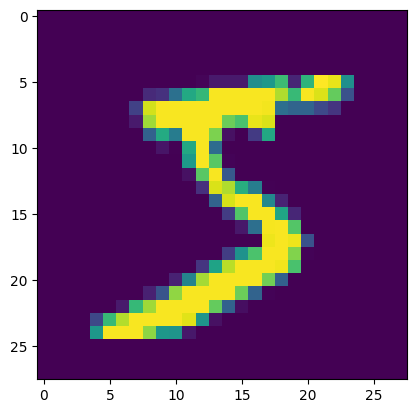

In [44]:
plt.imshow(images[0].reshape((28, 28)))

In [58]:
images_float = images.to(torch.float32)
images_normalized = images_float / 255.0
mnist_mean = torch.mean(images_normalized)
mnist_std = torch.std(images_normalized)

In [60]:
mnist_std

tensor(0.3081)

In [63]:
mnist_mean = images_normalized.mean(dtype=float)
print(mnist_mean)
images_std = (((images_normalized - mnist_mean)**2).mean())**0.5
images_std

tensor(0.1307, dtype=torch.float64)


tensor(0.3081)